# 3 · Background Baskets

Turn the sales shares into 100,000 ordinary shopping trips, with **nothing planted**. Any two items that show up
together here do so only because each is popular. This is the control group: later planted patterns must stand out
from it, and it tells us how much "frequent together" happens by pure chance.

Each basket is four decisions: **how many products → which products → which brand/pack of each → how many of each**.

**Done when:** my generator's basket statistics match the reference's, and the Gumbel shortcut draws products the same way.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thilimarketbasket.generate import make_catalog, popularity, background_baskets
from thilimarketbasket.mine import frequent_itemsets

catalog = make_catalog()
shares = popularity(catalog)
names = [item.name for item in catalog]
print(f"{len(catalog):,} SKUs, shares add up to {shares.sum():.0f}")

1,000 SKUs, shares add up to 1


## 1. How many products?

Trips vary: mostly small, a few big monthly shops. Model it as 2 + a negative binomial (mean 8, dispersion 4) —
at least 2 products, with a long tail of big baskets.

mean 8.01, median 7, 95th percentile 15, largest 40, smallest 2


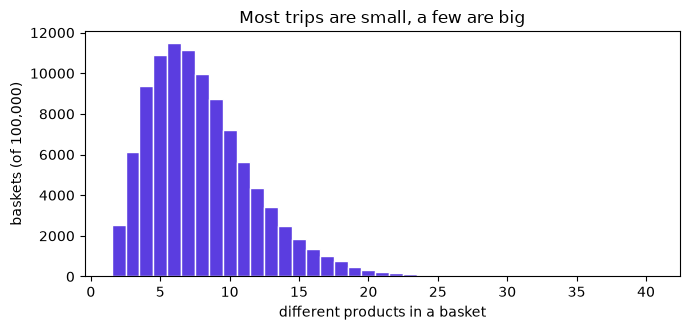

In [2]:
def my_basket_sizes(n_baskets, rng, mean=8.0, dispersion=4.0, minimum=2):
    """How many different products each basket holds."""
    extra_mean = mean - minimum
    p = dispersion / (dispersion + extra_mean)       # numpy's parameterisation of the negative binomial
    return minimum + rng.negative_binomial(dispersion, p, size=n_baskets)


rng = np.random.default_rng(0)
sizes = my_basket_sizes(100_000, rng)

print(f"mean {sizes.mean():.2f}, median {int(np.median(sizes))}, "
      f"95th percentile {int(np.percentile(sizes, 95))}, largest {sizes.max()}, smallest {sizes.min()}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(sizes, bins=range(2, sizes.max() + 2), color="#5b3de0", edgecolor="white", align="left")
ax.set_xlabel("different products in a basket")
ax.set_ylabel("baskets (of 100,000)")
ax.set_title("Most trips are small, a few are big")
plt.tight_layout()
plt.show()

Mean 8, median 7, and 1 trip in 20 has 15+. Keep the big baskets in mind — they come back at the end.

## 2. Which products?

Shoppers decide *what* first (dal), then *which* (brand, pack). So we draw products; a product's chance is the sum
of its SKUs' shares.

In [3]:
by_product = {}           # (category, product) -> positions of its SKUs in the catalogue
for position, item in enumerate(catalog):
    by_product.setdefault((item.category, item.base), []).append(position)

product_keys = list(by_product)
skus_of = [np.array(by_product[key]) for key in product_keys]
product_share = np.array([shares[s].sum() for s in skus_of])

print(f"{len(product_keys)} products, shares add up to {product_share.sum():.0f}")
print("most popular:", [key[1] for key in np.array(product_keys, dtype=object)[np.argsort(-product_share)[:5]]])

127 products, shares add up to 1
most popular: ['Milk', 'Sunflower Oil', 'Salt', 'Wheat Flour (Atta)', 'Onion']


Why not draw SKUs directly? Because then baskets end up with two milks:

In [4]:
rng = np.random.default_rng(1)
product_of = np.empty(len(catalog), dtype=int)
for number, skus in enumerate(skus_of):
    product_of[skus] = number

trials, same = 5000, 0
for _ in range(trials):
    picked = rng.choice(len(catalog), size=8, replace=False, p=shares)
    same += len(set(product_of[picked])) < 8
print(f"{same / trials:.0%} of direct-SKU baskets hold two brands or sizes of one product")

26% of direct-SKU baskets hold two brands or sizes of one product


About a quarter — real shoppers pick one milk. Drawing products first (without replacement) rules it out.

In [5]:
def pick_products(k, rng):
    """k different products, popular ones more likely."""
    return rng.choice(len(product_keys), size=k, replace=False, p=product_share)


print([product_keys[i][1] for i in pick_products(8, np.random.default_rng(3))])

['Poha', 'Sunflower Oil', 'Green Chilli', 'Potato Chips', 'Curd', 'Eggs', 'Toor Dal', 'Potato']


## 3. Which brand and pack?

Within the chosen product, pick one SKU with odds = its share ÷ the product's total.

In [6]:
def pick_sku(product, rng):
    """One SKU position for a product, with probability proportional to the SKUs' shares."""
    skus = skus_of[product]
    return rng.choice(skus, p=shares[skus] / shares[skus].sum())


toor = product_keys.index(("Pulses", "Toor Dal"))
tally = pd.Series([names[pick_sku(toor, rng)] for _ in range(20_000)]).value_counts(normalize=True)
print(tally.head(5).to_string(float_format=lambda x: f"{x:.1%}"))

Surya Grains Toor Dal 1 kg      51.4%
Kaveri Valley Toor Dal 1 kg     17.8%
Kaveri Valley Toor Dal 500 g     8.6%
Shubham Select Toor Dal 500 g    5.9%
Kaveri Valley Toor Dal 5 kg      5.9%


Surya Grains 1 kg ≈ half of Toor Dal, as section 2's weights said.

## 4. How many of each — and the full generator

Quantity 1/2/3/4 with probability 80/14/4/2%, written out as repeated lines like a till receipt. Then shuffle:
a basket is a bag, so the model mustn't be able to learn "popular items come first" from our drawing order.

In [7]:
QUANTITY_PROBS = (0.80, 0.14, 0.04, 0.02)


def my_background_baskets(n_baskets, seed=0):
    rng = np.random.default_rng(seed)
    sizes = my_basket_sizes(n_baskets, rng)
    baskets = []
    for k in sizes:
        lines = []
        for product in pick_products(k, rng):
            name = names[pick_sku(product, rng)]
            quantity = rng.choice(len(QUANTITY_PROBS), p=QUANTITY_PROBS) + 1
            lines += [name] * quantity
        baskets.append([lines[i] for i in rng.permutation(len(lines))])   # a shuffled basket: no order to learn
    return baskets


start = time.time()
mine = my_background_baskets(5_000)
print(f"{len(mine):,} baskets in {time.time() - start:.1f} s\n")
for basket in mine[:3]:
    print(len(basket), "items:", basket, "\n")

5,000 baskets in 0.6 s

3 items: ['Tomato 500 g', 'Ruchira Coconut Oil 500 ml', 'Pragati Masoor Dal 500 g'] 

9 items: ['Tomato 1 kg', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Maitri Foods Urad Dal 1 kg', 'Gokul Fresh Curd 200 g', 'Gokul Fresh Curd 200 g', 'Kaveri Valley Wheat Flour (Atta) 1 kg', 'Rasoi Royale Coriander Powder sachet 10 g', 'Gokul Fresh Buttermilk 200 ml', 'Kaveri Valley Poha 500 g'] 

3 items: ['Annadata Salt 1 kg', 'Pragati Basmati Rice 500 g', 'Sundar Sutra Shampoo Sachet Rs 1 sachet'] 



## The fast version: Gumbel top-k

The reference picks k products for every basket at once: score each product `log(share) + Gumbel noise` and take
the top k. That's mathematically the same as drawing one-at-a-time without replacement. Check it empirically:

In [8]:
n_trials = 20_000
rng_a, rng_b = np.random.default_rng(10), np.random.default_rng(11)

by_choice = np.zeros(len(product_keys))
for _ in range(n_trials):
    by_choice[pick_products(8, rng_a)] += 1

noise = rng_b.gumbel(size=(n_trials, len(product_keys)))
top8 = np.argpartition(-(np.log(product_share) + noise), 7, axis=1)[:, :8]
by_gumbel = np.bincount(top8.ravel(), minlength=len(product_keys))

print("share of baskets holding each product, two ways")
print(f"  correlation: {np.corrcoef(by_choice, by_gumbel)[0, 1]:.4f}")
print(f"  largest difference: {np.abs(by_choice - by_gumbel).max() / n_trials:.3f} (of 1.0)")

share of baskets holding each product, two ways
  correlation: 0.9989
  largest difference: 0.008 (of 1.0)


## Check against the reference

Different random draws, so we compare statistics, not baskets.

In [9]:
start = time.time()
baskets = background_baskets(100_000, catalog, shares, seed=0)
print(f"reference: 100,000 baskets in {time.time() - start:.1f} s")

def describe(baskets):
    lines = np.array([len(b) for b in baskets])
    distinct = np.array([len(set(b)) for b in baskets])
    return {"mean items (with repeats)": lines.mean(),
            "mean different items": distinct.mean(),
            "baskets with a repeated item": np.mean(lines > distinct)}

reference_5k = background_baskets(5_000, catalog, shares, seed=5)
pd.DataFrame({"ours (5,000)": describe(mine), "reference (5,000)": describe(reference_5k),
              "reference (100,000)": describe(baskets)}).round(2)

reference: 100,000 baskets in 0.8 s


,"ours (5,000)","reference (5,000)","reference (100,000)"
mean items (with repeats),10.20,10.20,10.25
mean different items,8.00,7.96,8.01
baskets with a repeated item,0.77,0.77,0.78


Same within noise. From here on: the 100,000 reference baskets.

## Do popular items turn up more?

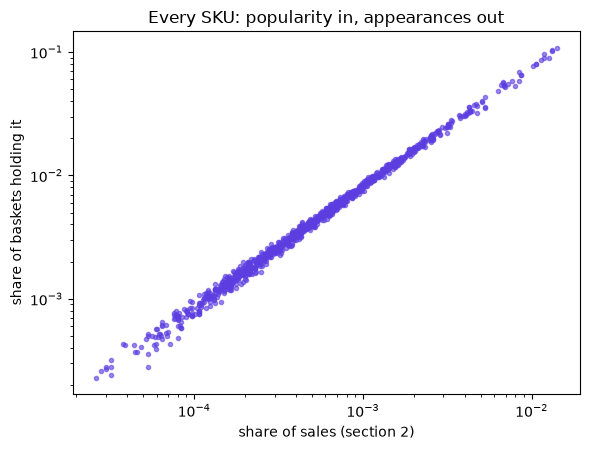

1000 of 1000 SKUs appear in at least one of 100,000 baskets
the most common SKU is in 10.8% of baskets, the rarest that appears in 0.0230%


In [10]:
appears = pd.Series([name for basket in baskets for name in set(basket)]).value_counts() / len(baskets)
df = pd.DataFrame({"share": shares, "appears_in": appears.reindex(names).fillna(0).values}, index=names)

fig, ax = plt.subplots(figsize=(6, 4.6))
ax.loglog(df["share"], df["appears_in"], ".", color="#5b3de0", alpha=0.6)
ax.set_xlabel("share of sales (section 2)")
ax.set_ylabel("share of baskets holding it")
ax.set_title("Every SKU: popularity in, appearances out")
plt.tight_layout()
plt.show()

print(f"{(df['appears_in'] > 0).sum()} of {len(df)} SKUs appear in at least one of 100,000 baskets")
print(f"the most common SKU is in {df['appears_in'].max():.1%} of baskets, the rarest that appears in {df.loc[df['appears_in'] > 0, 'appears_in'].min():.4%}")

A straight band: appearances ∝ share (~8–10× it, since a basket has ~8 chances). Noisy at the rare end because
the counts are tiny.

## What sells together by accident

Mine all pairs in ≥ 0.5% of baskets (the miner is a black box until section 6).

In [11]:
found = frequent_itemsets(baskets, min_support=0.005, max_size=2)
pairs = {itemset: support for itemset, support in found.items() if len(itemset) == 2}
print(f"{len(pairs)} pairs are in at least 0.5% of baskets, with nothing planted\n")

for itemset, support in sorted(pairs.items(), key=lambda kv: -kv[1])[:6]:
    print(f"  {support:.2%}   {' + '.join(sorted(itemset))}")

153 pairs are in at least 0.5% of baskets, with nothing planted

  1.31%   Onion 1 kg + Potato 1 kg
  1.23%   Potato 1 kg + Tomato 1 kg
  1.22%   Onion 1 kg + Tomato 1 kg
  1.12%   Coriander Leaves bunch + Onion 1 kg
  1.09%   Surya Grains Toor Dal 1 kg + Tomato 1 kg
  1.09%   Potato 1 kg + Surya Grains Toor Dal 1 kg


Onion + Potato at 1.3% purely from popularity — a planted 1% pair would hide among these. So support alone can't
tell real from accidental.

**Lift** = support(A and B) / (support(A) × support(B)); independent items should give 1.

In [12]:
lifts = []
for itemset, support in pairs.items():
    a, b = tuple(itemset)
    lifts.append(support / (found[frozenset([a])] * found[frozenset([b])]))
lifts = np.array(lifts)

print(f"lift of the {len(lifts)} accidental pairs: smallest {lifts.min():.2f}, median {np.median(lifts):.2f}, largest {lifts.max():.2f}")

lift of the 153 accidental pairs: smallest 1.01, median 1.12, largest 1.21


All a bit above 1. Suspect: basket size — big baskets hold many things at once, which nudges every pair up.
Test it by looking only at baskets with exactly 8 products:

In [13]:
size_of = np.array([len(set(b)) for b in baskets])
same_size = [b for b, k in zip(baskets, size_of) if k == 8]
print(f"{len(same_size):,} baskets with exactly 8 different items\n")

found8 = frequent_itemsets(same_size, min_support=0.005, max_size=2)
lifts8 = np.array([s / (found8[frozenset([a])] * found8[frozenset([b])])
                   for itemset, s in found8.items() if len(itemset) == 2
                   for a, b in [tuple(itemset)]])
print(f"lift of the {len(lifts8)} pairs in same-size baskets: median {np.median(lifts8):.2f}, "
      f"smallest {lifts8.min():.2f}, largest {lifts8.max():.2f}")

9,945 baskets with exactly 8 different items

lift of the 96 pairs in same-size baskets: median 0.96, smallest 0.71, largest 1.36


With size fixed the median drops to ~0.96 (just under 1, because drawing without replacement leaves one less slot).
So the extra lift was the basket-size mix. Data has structure even with nothing planted — which is why the answer
key will be the exact count of everything frequent, planted or accidental.

## Try it: bigger trips

In [14]:
for mean_size in (4, 8, 16):
    sample = background_baskets(20_000, catalog, shares, seed=2, mean_size=mean_size)
    pairs_found = frequent_itemsets(sample, min_support=0.005, max_size=2)
    n_pairs = sum(len(k) == 2 for k in pairs_found)
    print(f"mean {mean_size:>2} products per basket: {n_pairs:>5} pairs at 0.5% support, by accident")

mean  4 products per basket:     0 pairs at 0.5% support, by accident


mean  8 products per basket:   156 pairs at 0.5% support, by accident


mean 16 products per basket:  2825 pairs at 0.5% support, by accident


Bigger baskets → far more accidental pairs, so planted patterns would need to sit higher above the noise.

## What I built
A four-step basket generator (size → products without replacement → SKU → quantity, then shuffle), a check that the
vectorised Gumbel top-k version draws the same way, and a measurement of the chance background: 153 pairs at ≥0.5%
support with nothing planted, and a basket-size effect that pushes lift above 1.

## Test yourself

**1. Why draw products first and then a SKU, instead of drawing SKUs directly?**
Drawing SKUs directly puts two brands or sizes of the same product in about a quarter of baskets (two milks side by
side). Real shoppers pick one. Choosing the product first, without replacement, rules that out by construction.

**2. Why are the items in each basket shuffled?**
A basket is a bag, not a list. If items stayed in drawing order, a model could learn "popular things come first",
which is a quirk of our generator, not a fact about shopping.

**3. With nothing planted, why do most pairs have lift a bit above 1?**
Baskets come in very different sizes. A big basket holds many items, so any two items are more likely to be in it
together. Mixing small and big baskets gives every pair a small boost; holding size fixed brings the lift back to
about 1.

## My notes

Even with nothing planted, 153 pairs reach 0.5% support just because both items are popular, so support alone can't tell a real pattern from luck. Surprising: lift isn't 1 for independent items here; mixing small and big baskets pushes it to about 1.12.